# Codex diagnostic: NOAA OLR equivalent depths versus Gaussian background

**Agent-authored exploratory analysis.** This notebook is deliberately separate from the project's established analysis notebooks. All analysis and plotting code is defined here; it makes no changes to `src/` and writes no figure files. Figures appear only as notebook outputs.

**Question.** Do fitted equivalent-depth distributions of observed NOAA OLR wave events differ from those of events detected in matched stationary Gaussian background records? The comparison is made separately for Kelvin, MRG, n0EIG, n1ERW, and n1WIG. These figures are descriptive; they do not establish the significance of a preferred depth.


## Inputs and choices

- **Observations:** 1990-01-01 through 2010-12-31 NOAA OLR, with 1.5-standard-deviation Hilbert-envelope detection and raw sinusoid fitting on active event pixels.
- **Background:** 1,000 held-out 21-year Gaussian realizations per wave, drawn from the saved WK99-style 1-2-1 smoothed spectrum. Every background event passed through the same detector, fit, and dispersion inversion. `catalog_index.1000-2000.csv` is the completed audit.
- **Screened selection:** `keep_for_histogram == True`, incorporating fit success, R², search-edge, spatial-cycle, temporal-cycle, and dispersion-validity screens.
- **Relaxed selection:** all events with a successful fit and finite, positive, dispersion-valid `h_eff_m`. No R², search-edge, spatial-cycle, or temporal-cycle cutoff is applied. Events without a valid fitted depth cannot appear on a depth axis.
- **Binning:** 50 equal-width bins in `log10(h_eff / m)` from 0.5 to 10,000 m. The table reports the fraction outside this display range; those events remain in each selection's denominator.
- **Comparison:** each curve is a fraction of that record's selected events per decade of depth. The orange band is the **pointwise** 2.5th–97.5th percentile of the 1,000 full-record background densities. It is not a simultaneous confidence band or a multiple-testing-adjusted significance test. No 1% or 5% peak-amplitude threshold is imposed: this analysis compares the full detected-event populations.

Inputs must be available through the project's `data/` directory. Run from the project root or `notebooks/` with the `cmip6_equiv_depth_distributions` Python kernel on Levante.


In [1]:
%matplotlib inline

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data").is_dir():
    raise FileNotFoundError("Run from the project root or notebooks/ with data/ configured")
DATA_DIR = PROJECT_ROOT / "data"
NULL_RUN = (DATA_DIR / "wave_significance" / "gaussian_calibration_wk99_121"
            / "NOAA_OLR.observations.not_applicable.1990-2010.b898b1ae4307")
CATALOG_DIR = NULL_RUN / "component_fit_catalogs"
WAVES = ("Kelvin", "MRG", "n0EIG", "n1ERW", "n1WIG")
SELECTIONS = {"screened": "Quality-screened", "relaxed": "All valid-depth fits"}
EDGES_M = np.geomspace(0.5, 10_000.0, 51)
LOG_WIDTH = np.diff(np.log10(EDGES_M))

with (NULL_RUN / "manifest.json").open() as handle:
    manifest = json.load(handle)
if manifest["status"] != "complete" or manifest["configuration"]["n_validation"] != 1000:
    raise RuntimeError("The expected completed NOAA null ensemble is unavailable")
index = pd.read_csv(CATALOG_DIR / "catalog_index.1000-2000.csv")
if (len(index) != 5000 or index.duplicated(["wave_type", "realization"]).any()
        or set(index.wave_type) != set(WAVES)):
    raise RuntimeError("Expected exactly 1,000 audited null catalogs per wave")

observed_catalogs = {}
for wave in WAVES:
    matches = [p for p in DATA_DIR.glob(
        f"NOAA_OLR.{wave}.19900101-20101231.*.ds1p5.component.*.csv")
        if ".pilot" not in p.name]
    if len(matches) != 1:
        raise RuntimeError(f"Expected one full observed component catalog for {wave}; found {matches}")
    path = matches[0]
    with path.with_suffix(".json").open() as handle:
        metadata = json.load(handle)
    config = metadata["configuration"]
    if (metadata["status"] != "complete" or config["fit_support"] != "component"
            or config["detection"]["detection_sigma"] != 1.5
            or config["wave_type"] != wave or config["max_events"] is not None):
        raise RuntimeError(f"Unexpected observed catalog provenance: {path}")
    observed_catalogs[wave] = (path, metadata)
print("Inputs: five observed catalogs and", len(index), "audited null catalogs")


Inputs: five observed catalogs and 5000 audited null catalogs


In [2]:
def selected_depths(path):
    """Return both depth selections and the candidate count from one catalog."""
    frame = pd.read_csv(
        path, usecols=["h_eff_m", "keep_for_histogram", "fit_success", "dispersion_valid"],
        dtype={"h_eff_m": "float64", "keep_for_histogram": "boolean",
               "fit_success": "boolean", "dispersion_valid": "boolean"},
    )
    depth = frame.h_eff_m.to_numpy(dtype=float)
    valid_depth = np.isfinite(depth) & (depth > 0)
    screened = frame.keep_for_histogram.fillna(False).to_numpy(dtype=bool)
    relaxed = (frame.fit_success.fillna(False).to_numpy(dtype=bool)
               & frame.dispersion_valid.fillna(False).to_numpy(dtype=bool)
               & valid_depth)
    if np.any(screened & ~relaxed):
        raise RuntimeError(f"Quality-screened events lack a valid depth: {path}")
    return {"screened": depth[screened], "relaxed": depth[relaxed]}, len(frame)


results = {}
summary_rows = []
for wave in WAVES:
    observed_path, observed_metadata = observed_catalogs[wave]
    observed, observed_candidates = selected_depths(observed_path)
    if observed_candidates != observed_metadata["catalog_candidates"]:
        raise RuntimeError(f"Observed row count differs from provenance: {wave}")
    records = index.loc[index.wave_type.eq(wave)].sort_values("realization")
    if records.realization.tolist() != list(range(1000, 2000)):
        raise RuntimeError(f"Missing or unordered null realizations for {wave}")
    null_hist = {key: np.empty((1000, len(LOG_WIDTH)), dtype=np.int32)
                 for key in SELECTIONS}
    null_n = {key: np.empty(1000, dtype=np.int32) for key in SELECTIONS}
    for j, row in enumerate(records.itertuples(index=False)):
        depths, candidates = selected_depths(PROJECT_ROOT / row.catalog)
        if candidates != row.candidates or len(depths["screened"]) != row.keep_for_histogram:
            raise RuntimeError(f"Null catalog differs from the audited index: {row.catalog}")
        for key in SELECTIONS:
            null_n[key][j] = len(depths[key])
            null_hist[key][j] = np.histogram(depths[key], bins=EDGES_M)[0]
    results[wave] = {}
    for key in SELECTIONS:
        observed_hist = np.histogram(observed[key], bins=EDGES_M)[0]
        observed_n = len(observed[key])
        results[wave][key] = dict(observed_hist=observed_hist, observed_n=observed_n,
                                  null_hist=null_hist[key], null_n=null_n[key])
        summary_rows.append(dict(
            wave_type=wave, selection=key, observed_candidates=observed_candidates,
            observed_depth_events=observed_n,
            null_median_depth_events=int(np.median(null_n[key])),
            null_95pct_record_range=(int(np.quantile(null_n[key], 0.025)),
                                      int(np.quantile(null_n[key], 0.975))),
            observed_outside_plot_pct=100 * (observed_n - observed_hist.sum()) / observed_n,
            null_outside_plot_pct=100 * (null_n[key].sum() - null_hist[key].sum())
                                  / null_n[key].sum(),
        ))
    print(f"{wave}: observed {observed_candidates} candidates; 1,000 null records processed")

summary = pd.DataFrame(summary_rows)
display(summary.round({"observed_outside_plot_pct": 2, "null_outside_plot_pct": 2}))


Kelvin: observed 2897 candidates; 1,000 null records processed


MRG: observed 2964 candidates; 1,000 null records processed


n0EIG: observed 3660 candidates; 1,000 null records processed


n1ERW: observed 1029 candidates; 1,000 null records processed


n1WIG: observed 3836 candidates; 1,000 null records processed


,wave_type,selection,observed_candidates,observed_depth_events,null_median_depth_events,null_95pct_record_range,observed_outside_plot_pct,null_outside_plot_pct
0,Kelvin,screened,2897,767,1098,"(1052, 1144)",0.00,0.00
1,Kelvin,relaxed,2897,2897,4263,"(4165, 4362)",0.00,0.00
2,MRG,screened,2964,806,1063,"(1018, 1109)",0.50,0.21
3,MRG,relaxed,2964,2847,3220,"(3133, 3303)",2.18,1.77
4,n0EIG,screened,3660,1409,1880,"(1818, 1940)",0.00,0.00
5,n0EIG,relaxed,3660,3660,4054,"(3969, 4143)",0.00,0.00
6,n1ERW,screened,1029,215,388,"(362, 416)",0.00,0.00
7,n1ERW,relaxed,1029,1029,1392,"(1337, 1448)",0.00,0.00
8,n1WIG,screened,3836,2036,2446,"(2377, 2519)",0.00,0.00
9,n1WIG,relaxed,3836,3836,4433,"(4343, 4533)",0.00,0.00


## Quality-screened equivalent-depth distributions

These five figures use the existing `keep_for_histogram` rule. The blue curve is the single observed 21-year record; the orange curve and band summarize 1,000 independent 21-year background records. Density is normalized within each record by **all** selected depths, including rare values outside the displayed x range.


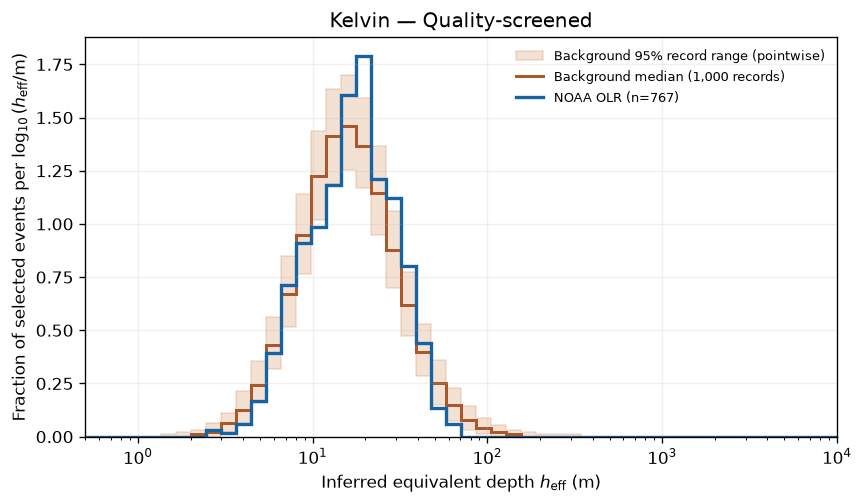

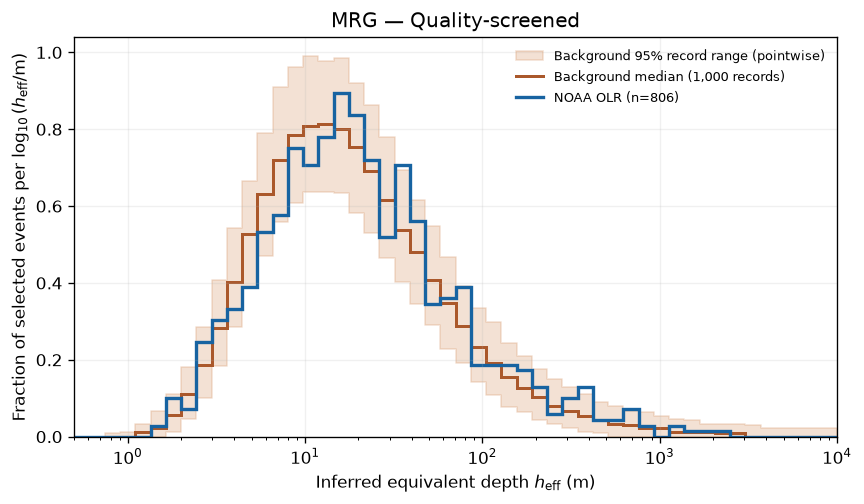

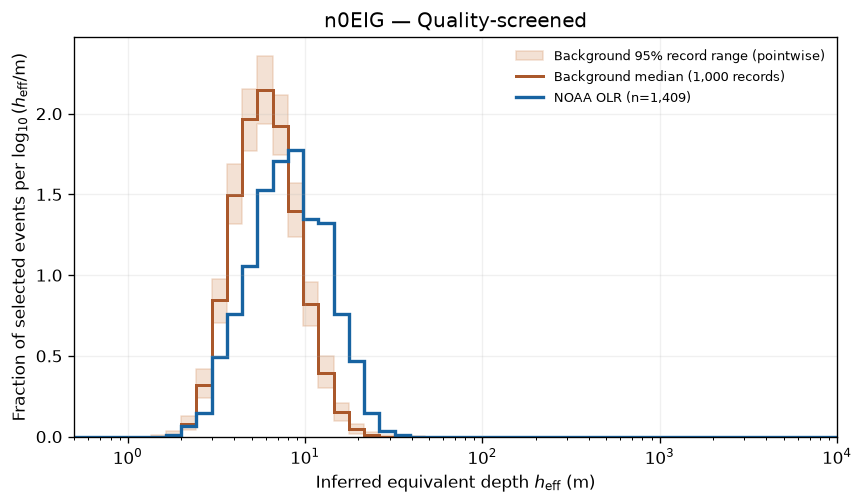

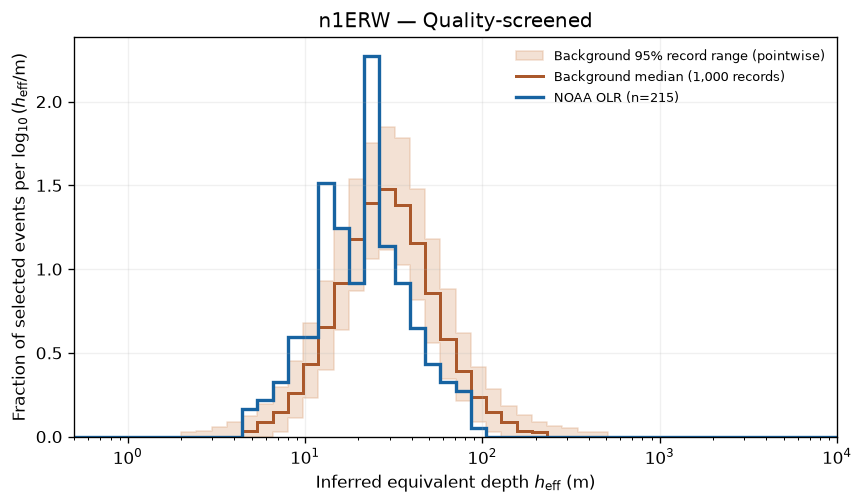

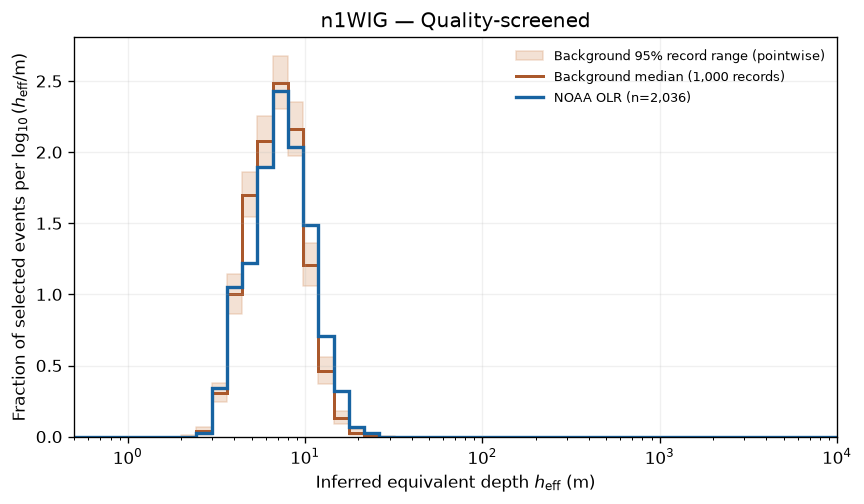

In [3]:
def plot_depth_distribution(wave, selection):
    """Display one standalone observed-versus-null depth-density panel; save no file."""
    result = results[wave][selection]
    observed_n = result["observed_n"]
    null_n = result["null_n"]
    if observed_n == 0 or np.any(null_n == 0):
        raise RuntimeError(f"No selected events for {wave}/{selection}")
    observed_density = result["observed_hist"] / observed_n / LOG_WIDTH
    null_density = result["null_hist"] / null_n[:, None] / LOG_WIDTH[None, :]
    lower, median, upper = np.quantile(null_density, [0.025, 0.5, 0.975], axis=0)

    fig, ax = plt.subplots(figsize=(7.3, 4.3), dpi=120)
    ax.fill_between(EDGES_M, np.r_[lower, lower[-1]], np.r_[upper, upper[-1]],
                    step="post", color="#d28b57", alpha=0.25,
                    label="Background 95% record range (pointwise)")
    ax.stairs(median, EDGES_M, color="#aa582b", linewidth=1.8,
              label="Background median (1,000 records)")
    ax.stairs(observed_density, EDGES_M, color="#1763a1", linewidth=2.0,
              label=f"NOAA OLR (n={observed_n:,})")
    ax.set(xscale="log", xlim=(EDGES_M[0], EDGES_M[-1]), ylim=(0, None),
           xlabel=r"Inferred equivalent depth $h_{\mathrm{eff}}$ (m)",
           ylabel=r"Fraction of selected events per $\log_{10}(h_{\mathrm{eff}}/\mathrm{m})$",
           title=f"{wave} — {SELECTIONS[selection]}")
    ax.grid(alpha=0.18)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


for wave in WAVES:
    plot_depth_distribution(wave, "screened")


## Relaxed selection: all events with a valid fitted depth

This repeats the comparison after removing the R², search-edge, spatial-cycle, and temporal-cycle screens. A successful fit and a finite, positive, dispersion-valid depth remain necessary to place an event on the horizontal axis. Comparing these panels with the screened panels shows how much of the apparent distribution depends on fit-quality selection.


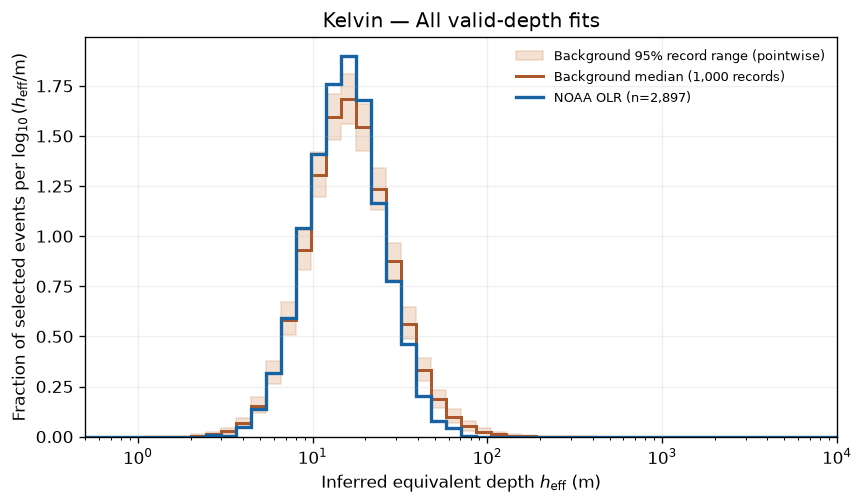

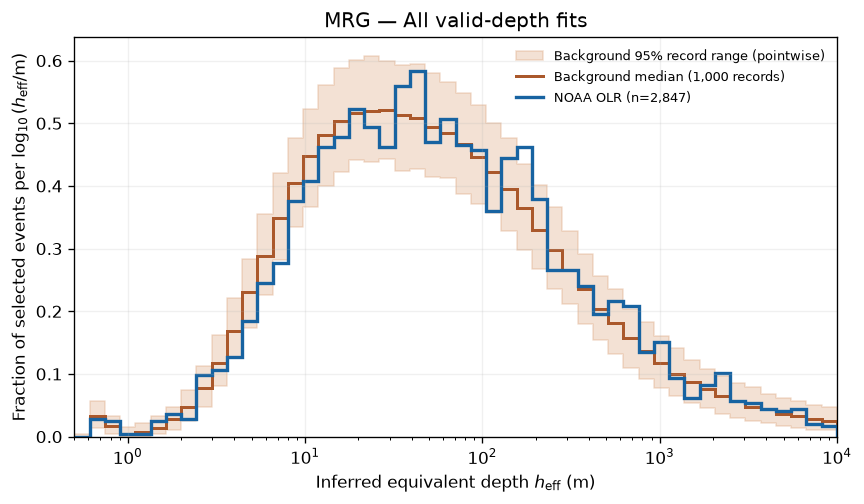

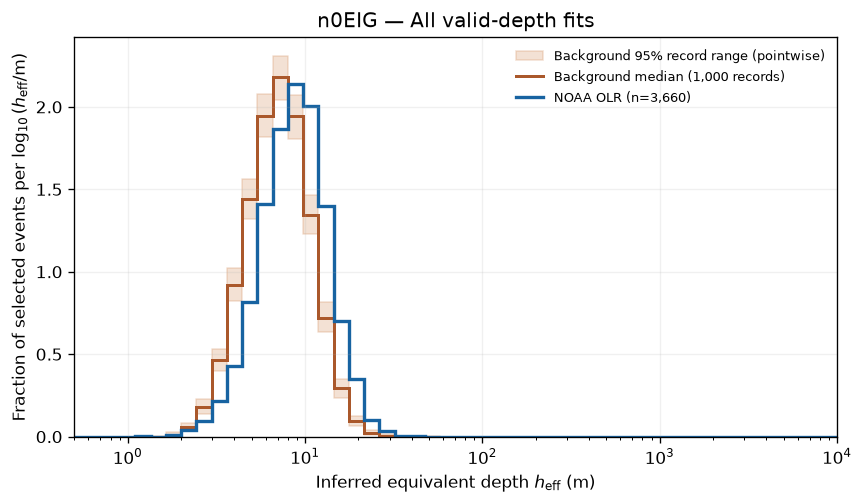

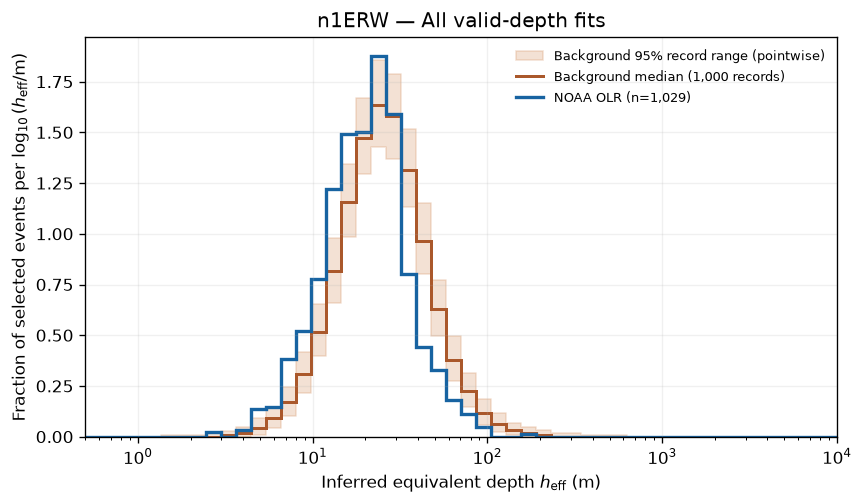

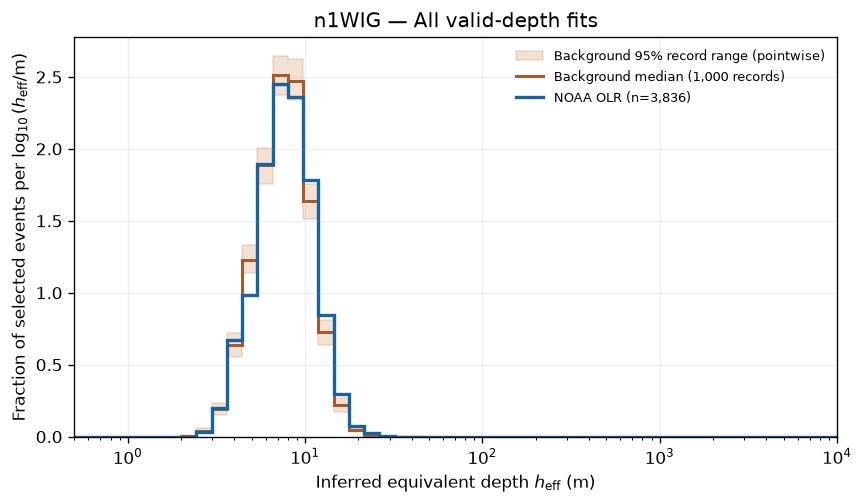

In [4]:
for wave in WAVES:
    plot_depth_distribution(wave, "relaxed")


## Interpretation and limits

Across all five wave types, NOAA has fewer selected depth events than the median of the 1,000 Gaussian records under both quality selections (see the count table). This is a comparison of event counts; the density panels compare **distribution shapes after within-record normalization**. The count difference alone does not establish that any depth range is preferred.

A concentration in the observed curve must be judged against the **empirical** background curve, which need not be flat: filters, search boxes, fit geometry, dispersion inversion, and selection rules can themselves produce preferred fitted depths. The plotted percentile bands are pointwise descriptions of complete null records. Searching many depths and five wave types requires a separate global or multiplicity-aware test before calling any feature statistically significant. The background model is stationary Gaussian and may miss non-Gaussian tails or local/seasonal variability. These are fitted equivalent depths under the project's zero-background-wind dispersion assumptions, not direct measurements of vertical mode depth.

No figures are saved outside this notebook.
